In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

data = pd.read_csv("../data/zomato_ncr_clean.csv")
rated = data[data["is_rated"]]

          restaurants  avg_rating  avg_cost  median_votes
is_chain                                                 
False            4709        3.31    731.64          37.0
True             1099        3.17    541.17          55.0


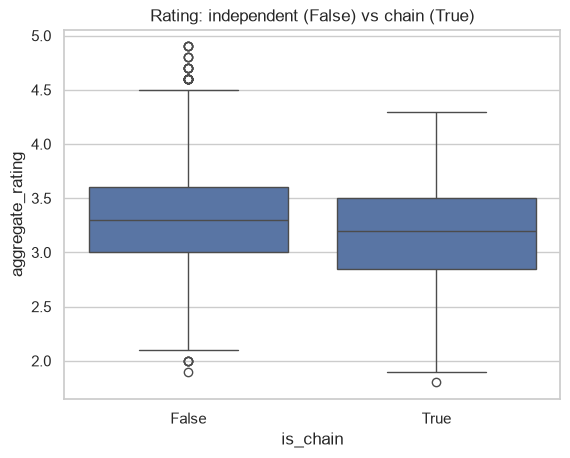

In [2]:
chain_summary = rated.groupby("is_chain").agg(
    restaurants=("restaurant_id", "count"),
    avg_rating=("aggregate_rating", "mean"),
    avg_cost=("average_cost_for_two", "mean"),
    median_votes=("votes", "median"),
).round(2)
print(chain_summary)

sns.boxplot(data=rated, x="is_chain", y="aggregate_rating")
plt.title("Rating: independent (False) vs chain (True)")
plt.show()

In [3]:
loc = rated.groupby(["city", "locality"]).agg(
    restaurants=("restaurant_id", "count"),
    avg_rating=("aggregate_rating", "mean"),
    avg_cost=("average_cost_for_two", "mean"),
).round(2).reset_index()

loc = loc[loc["restaurants"] >= 20]     # ignore localities with too few restaurants
print(len(loc), "localities")

print(loc.sort_values("avg_rating", ascending=False).head(10))
print(loc.sort_values("avg_rating").head(10))

103 localities
          city                              locality  restaurants  avg_rating  \
104    Gurgaon                             Sector 29           38        3.89   
47     Gurgaon             Cyber Hub, DLF Cyber City           41        3.86   
211  New Delhi                     Hauz Khas Village           24        3.85   
386      Noida  DLF Mall of India, Sector 18,  Noida           31        3.84   
54     Gurgaon                           DLF Phase 4           21        3.80   
245  New Delhi                           Khan Market           43        3.80   
173  New Delhi                       Connaught Place          119        3.78   
327  New Delhi           Select Citywalk Mall, Saket           25        3.76   
329  New Delhi                           Shahpur Jat           26        3.72   
205  New Delhi                Greater Kailash (GK) 1           66        3.70   

     avg_cost  
104   1394.74  
47    1321.95  
211   1402.08  
386    946.77  
54     750.00

In [4]:
cuisine_df = rated.assign(cuisine=rated["cuisines"].str.split(", ")).explode("cuisine")

cg = cuisine_df.groupby("cuisine").agg(
    restaurants=("restaurant_id", "count"),
    avg_rating=("aggregate_rating", "mean"),
    avg_votes=("votes", "mean"),
).round(2)

cg = cg[cg["restaurants"] >= 30]
print(cg.sort_values("avg_rating", ascending=False).head(10))

               restaurants  avg_rating  avg_votes
cuisine                                          
Asian                  146        3.80     495.02
European                85        3.79     626.95
Mediterranean           59        3.78     667.02
Mexican                 74        3.70     389.41
Thai                   171        3.63     247.46
Italian                497        3.61     419.87
Japanese                74        3.61     227.76
Continental            510        3.60     372.33
Seafood                 50        3.59     333.48
Lebanese                53        3.55     387.51
